**Purpose:** Imports OpenCV and NumPy for edge-filter implementation.

In [27]:
import cv2
import numpy as np

**Purpose:** Defines a Laplacian filter using a 3-by-3 neighborhood.

In [ ]:
def laplacian_filter(img):
    mask = np.array([
        [0, -1, 0],
        [-1, 4, -1],
        [0, -1, 0]
    ])
    r,c = img.shape
    result = np.zeros_like(img).astype(np.uint8)
    
    for i in range(1, r-1):
        for j in range(1, c-1):
            region = img[i-1:i+2, j-1:j+2].astype(np.int16)
            lap = np.sum(region* mask)
            pixel = int(img[i,j])+lap
            
            result[i][j] = max(0,min(255,pixel))
    
    return result



**Purpose:** Defines a gradient filter using Sobel kernels.

In [ ]:
def gradient_filter(img):
    sobel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])

    sobel_y = np.array([
        [-1, -2, -1],
        [0, 0, 0],
        [1, 2, 1]
    ])
    
    r,c = img.shape
    result = np.zeros_like(img).astype(np.uint8)
    
    for i in range(1, r - 1):
        for j in range(1, c - 1):
            region = img[i-1:i+2, j-1:j+2].astype(np.int16)
            
            gx = np.sum(region* sobel_x)
            gy = np.sum(region* sobel_y)
            magnitude = np.sqrt(gx**2 + gy**2)
            pixel = int(img[i,j])+ int(magnitude)
            
            result[i,j] = max(0, min(255,pixel))

    return result
    

**Purpose:** Applies both filters to the cat image and displays their results.

Text(0.5, 1.0, 'Gradient Filter')

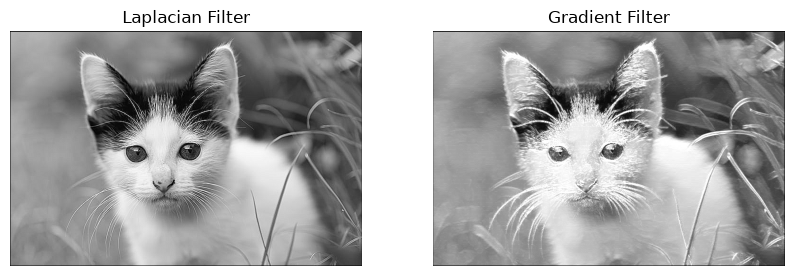

In [31]:
img = cv2.imread('../cat.jpg',0)

laplacian = laplacian_filter(img)
gradient = gradient_filter(img)

import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(laplacian,cmap='gray')
plt.title('Laplacian Filter')
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(gradient,cmap='gray')
plt.axis('off')
plt.title("Gradient Filter")

**Purpose:** This cell is intentionally left blank.